## Ejercicio 8

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

In [5]:
b7 = A7 @ x_fantoma
rng = np.random.default_rng(2026)
z = rng.standard_normal(b7.size)
escala = np.sqrt(np.mean(b7**2))

In [6]:
sigma = 0.06
b_sigma = b7 + sigma * escala * z

### Inciso a)

El costo $E(x)=\frac12\|A_7x-b_\sigma\|^2$ mide la discrepancia entre las mediciones
simuladas y las observadas. El factor $1/2$ simplifica la derivada.
El gradiente $A_7^T(A_7x-b_\sigma)$ indica la dirección de mayor aumento del costo.
La Hessiana $H=A_7^TA_7$ describe su curvatura y no depende de $x$.

Para cualquier $v$, se cumple $v^THv=\|A_7v\|^2$. Como `A7` tiene rango columna completo,
esta cantidad es positiva para $v\ne0$: $H$ es simétrica definida positiva.

In [7]:
def costo(x, A, b):
    residuo = A @ x - b
    return 0.5 * np.dot(residuo, residuo)

def gradiente(x, A, b):
    return A.T @ (A @ x - b)

H = A7.T @ A7
print("¿H es simétrica?", np.allclose(H, H.T))
print("Menor autovalor:", np.linalg.eigvalsh(H)[0])
assert np.allclose(H, H.T)
assert np.linalg.eigvalsh(H)[0] > 0

¿H es simétrica? True
Menor autovalor: 0.5132736028183065


### Inciso b)

In [8]:
def gradiente_descendiente(A, b, alpha, max_iter=10000, tol=1e-8,
                          D=None, lam=0.0, x_ref=None):
    x = np.zeros(A.shape[1], dtype=float)
    AT = A.T
    DT = None if D is None else D.T
    costos = []
    normas_gradiente = []
    errores = []
    norma_inicial = None
    motivo = "máximo de iteraciones"

    t = 0
    for t in range(max_iter + 1):
        residuo = A @ x - b
        costo = 0.5 * np.dot(residuo, residuo)
        grad = AT @ residuo

        if D is not None and lam != 0:
            diferencias = D @ x
            costo += 0.5 * lam * np.dot(diferencias, diferencias)
            grad = grad + lam * (DT @ diferencias)

        norma_grad = np.linalg.norm(grad)
        if norma_inicial is None:
            norma_inicial = norma_grad

        costos.append(float(costo))
        normas_gradiente.append(float(norma_grad))
        # La referencia se usa solamente para registrar el error, nunca para detenernos.
        if x_ref is not None:
            errores.append(np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref))

        if not np.isfinite(costo) or costo > 1e25:
            motivo = "costo divergente"
            break
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break
        if t == max_iter:
            break

        x = x - alpha * grad

    return {"x": x, "costos": np.array(costos),
            "normas_gradiente": np.array(normas_gradiente),
            "errores": np.array(errores), "iteraciones": t, "motivo": motivo}

Tasa de aprendizaje: 0.027424756403856825
Iteraciones: 1149
Parada: tolerancia del gradiente
Costo final: 0.14153222462341675
Norma final del gradiente: 6.674889790112596e-09


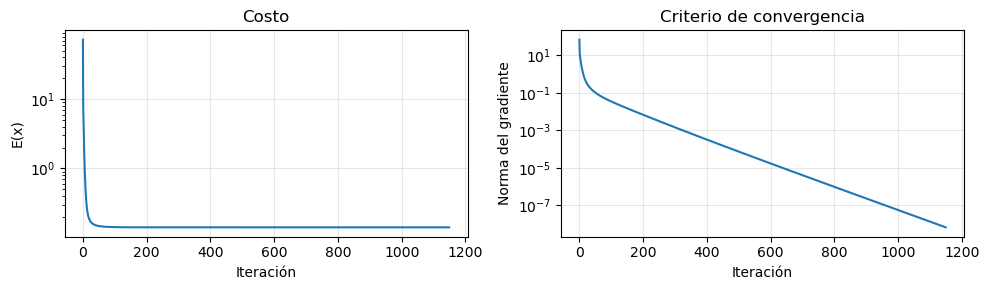

In [9]:
mu_max = np.linalg.eigvalsh(H)[-1]
alpha = 1.0 / mu_max
resultado_gd = gradiente_descendiente(A7, b_sigma, alpha, max_iter=10000, tol=1e-10)
x_gd = resultado_gd["x"]
print("Tasa de aprendizaje:", alpha)
print("Iteraciones:", resultado_gd["iteraciones"])
print("Parada:", resultado_gd["motivo"])
print("Costo final:", resultado_gd["costos"][-1])
print("Norma final del gradiente:", resultado_gd["normas_gradiente"][-1])

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].semilogy(resultado_gd["costos"])
axs[0].set_ylabel("E(x)")
axs[0].set_title("Costo")
axs[1].semilogy(resultado_gd["normas_gradiente"])
axs[1].set_ylabel("Norma del gradiente")
axs[1].set_title("Criterio de convergencia")
for ax in axs:
    ax.set_xlabel("Iteración")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Inciso c)

Mayor autovalor de H: 36.46340500801557
Intervalo estable: 0 < alpha < 0.05484951280771365
Factor 0.2: costo inicial = 7.2190e+01, costo final = 1.5213e-01
Factor 1.0: costo inicial = 7.2190e+01, costo final = 1.4157e-01
Factor 1.8: costo inicial = 7.2190e+01, costo final = 1.4153e-01
Factor 2.2: costo inicial = 7.2190e+01, costo final = 1.0994e+25


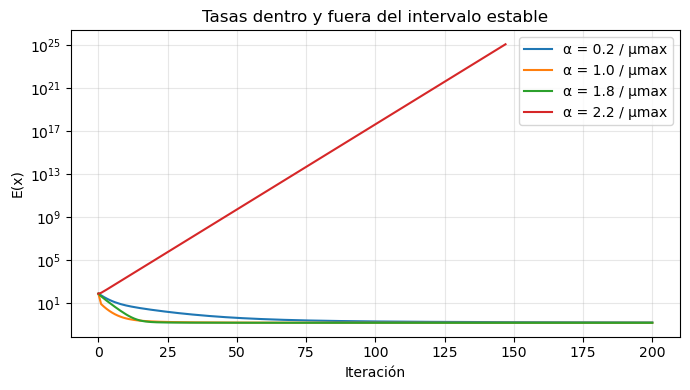

In [10]:
limite_alpha = 2.0 / mu_max
print("Mayor autovalor de H:", mu_max)
print("Intervalo estable: 0 < alpha <", limite_alpha)

factores = [0.2, 1.0, 1.8, 2.2]
fig, ax = plt.subplots(figsize=(7, 4))
for factor in factores:
    tasa = factor / mu_max
    resultado = gradiente_descendiente(A7, b_sigma, tasa, max_iter=200, tol=1e-10)
    ax.semilogy(resultado["costos"], label=f"α = {factor:.1f} / μmax")
    print(f"Factor {factor:.1f}: costo inicial = {resultado['costos'][0]:.4e}, "
          f"costo final = {resultado['costos'][-1]:.4e}")
    if factor < 2:
        assert np.all(np.diff(resultado["costos"]) <= 1e-9)
ax.set_xlabel("Iteración")
ax.set_ylabel("E(x)")
ax.set_title("Tasas dentro y fuera del intervalo estable")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Si $e_t=x_t-\hat x$, entonces $e_{t+1}=(I-\alpha H)e_t$. En cada dirección propia,
el error se multiplica por $1-\alpha\mu_i$. Para que disminuya en todas las direcciones,
necesitamos $|1-\alpha\mu_i|<1$, lo que da $0<\alpha<2/\mu_{\max}$.

Las tasas dentro del intervalo producen descenso del costo. Una tasa muy pequeña avanza
lentamente. Para $\alpha=2{,}2/\mu_{\max}$, la componente correspondiente al mayor autovalor
crece y el costo diverge. El extremo $2/\mu_{\max}$ no garantiza convergencia porque esa
componente del error puede oscilar sin disminuir.

### Inciso d)

In [11]:
x0 = np.zeros(n**2)
p0 = np.linalg.solve(H, gradiente(x0, A7, b_sigma))
x_newton = x0 - p0
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]

print("Pasos de Newton: 1")
print("Norma del gradiente después del paso:", np.linalg.norm(gradiente(x_newton, A7, b_sigma)))
print("Diferencia respecto de lstsq:", np.linalg.norm(x_newton - x_lstsq))
assert np.allclose(x_newton, x_lstsq, atol=1e-10)

Pasos de Newton: 1
Norma del gradiente después del paso: 1.685376233092072e-14
Diferencia respecto de lstsq: 1.1982796382043795e-14


La ecuación de Newton es $Hp_t=Hx_t-A_7^Tb_\sigma$. Como $H$ es invertible,

$$x_{t+1}=x_t-H^{-1}(Hx_t-A_7^Tb_\sigma)=H^{-1}A_7^Tb_\sigma.$$

En una cuadrática, el modelo de segundo orden coincide con la función completa. Por eso
un solo paso con tasa uno llega al minimizador, salvo redondeo. En el código resolvemos el
sistema con `solve`, sin construir la inversa de $H$.

### Inciso e)

Método                  Costo    Norma gradiente    Error relativo   Distancia a lstsq
Gradiente        1.415322e-01       6.674890e-09      1.133349e-01        1.299314e-08
Newton           1.415322e-01       1.685376e-14      1.133349e-01        1.198280e-14
lstsq            1.415322e-01       9.242411e-14      1.133349e-01        0.000000e+00


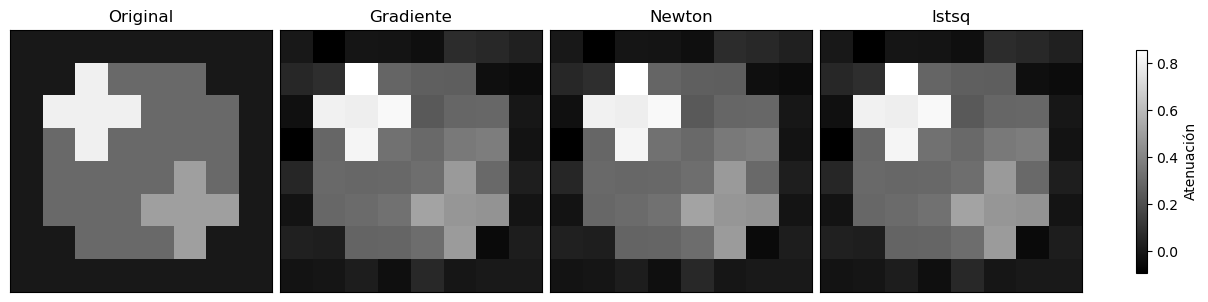

In [12]:
metodos = {"Gradiente": x_gd, "Newton": x_newton, "lstsq": x_lstsq}
print(f"{'Método':<14} {'Costo':>14} {'Norma gradiente':>18} {'Error relativo':>17} {'Distancia a lstsq':>19}")
for nombre, x in metodos.items():
    error = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
    print(f"{nombre:<14} {costo(x, A7, b_sigma):14.6e} "
          f"{np.linalg.norm(gradiente(x, A7, b_sigma)):18.6e} {error:17.6e} "
          f"{np.linalg.norm(x - x_lstsq):19.6e}")
assert np.allclose(x_gd, x_lstsq, atol=1e-7)

vmin = min(X_fantoma.min(), min(x.min() for x in metodos.values()))
vmax = max(X_fantoma.max(), max(x.max() for x in metodos.values()))
fig, axs = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, nombre, x in zip(axs, ["Original"] + list(metodos), [x_fantoma] + list(metodos.values())):
    im = ax.imshow(x.reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(nombre)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(axs[0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()

Los tres métodos llegan a la misma reconstrucción dentro de sus tolerancias. El error
respecto del fantoma sigue siendo aproximadamente 0,113 porque las mediciones contienen ruido.
Newton y `lstsq` no eliminan ese ruido: resuelven el mismo problema que gradiente descendiente.
La diferencia está en el procedimiento y el costo de cálculo. Gradiente necesita una tasa
y varias iteraciones; Newton resuelve un sistema con la Hessiana en un paso; `lstsq` obtiene
directamente una solución de mínimos cuadrados, sin elegir una tasa de aprendizaje.